In [1]:
#Import all importent depandancys
#LangGraph 
from langgraph.graph import StateGraph, START, END
# State management
from typing import TypedDict, Annotated
from IPython.display import Image, display
import operator

In [2]:

# 1. Define state without a reducer
class AgentState(TypedDict):
    message: str


In [3]:
def node_a(state: AgentState):
    return {"message": ["Hello from Node A"]}

def node_b(state: AgentState):
    return {"message": ["Hello from Node B"]}

In [4]:
# 4. Build graph
builder = StateGraph(AgentState)

builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)

# Both nodes execute in parallel
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

In [5]:

# 5. Compile graph
graph = builder.compile()


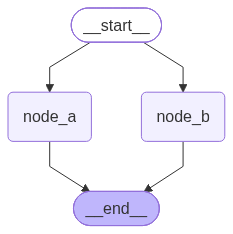

In [6]:
#Print Graph
display(
    Image(graph.get_graph().draw_mermaid_png())
)

In [7]:
# 6. Execute graph
result = graph.invoke({
    "message": "Initial message"
})

print("Final Result:", result)


InvalidUpdateError: At key 'message': Can receive only one value per step. Use an Annotated key to handle multiple values.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/INVALID_CONCURRENT_GRAPH_UPDATE